# THAI TAY: ทายราคาวัสดุก่อสร้างล่วงหน้า 1–3 เดือน

notebook นี้เล่าทุกขั้นตอนที่ทีมทำ ตั้งแต่ข้อมูลจนถึงผลลัพธ์ ผลทุกช่องบันทึกไว้แล้ว อ่านได้เลยโดยไม่ต้องรัน

## ผลสั้น ๆ

| คำถาม | คำตอบ |
|---|---|
| ทายอะไร | ราคาวัสดุงานโครงสร้าง 188 รายการ ราคากรุงเทพฯ ของ สนค. ล่วงหน้า 1, 2, 3 เดือน |
| ลองกี่โมเดล | 9 แบบ ตั้งแต่ Naive ไปจนถึง LightGBM, Random Forest และ LSTM |
| โมเดลไหนดีที่สุด | Naive (ราคาเดือนหน้า = ราคาเดือนนี้) ไม่มีโมเดลไหนชนะได้ทั้งช่วง Validation และ Test |
| แม่นแค่ไหน | ปีปกติ ทาย 1 เดือนผิดเฉลี่ย 0.67% ปีล่าสุดที่เหล็กแกว่งแรง ผิด 1.75% (1 เดือน) ถึง 5.06% (3 เดือน) |
| ML ช่วยตรงไหน | ป้าย "ราคามีโอกาสเปลี่ยน" ใช้ LightGBM ขึ้นป้ายแล้วราคาเปลี่ยนจริง 80% |
| ทำไมทายยาก | คอนกรีตและเสาเข็มราคาเท่าเดิมราว 9 ใน 10 เดือน ส่วนเหล็กขยับทุกเดือน แต่ข้อมูลที่หาได้ไม่มีตัวไหนรู้ก่อนว่าจะขึ้นหรือลง |

## วิธีรันเอง (ไม่บังคับ)

1. กด **Runtime → Run all**
2. ช่องแรกจะขอไฟล์ ให้เลือก `thaitay_colab.zip` ที่ได้มาพร้อม notebook
3. รอราว 3 นาที การทดลองเต็มใช้เวลาเกือบ 2 ชั่วโมง notebook จึงโหลดผลที่บันทึกไว้มาแสดง (ถ้าจะรันใหม่ทั้งหมด ดูภาคผนวก)

ช่องโค้ดส่วนใหญ่ซ่อนไว้ ดับเบิลคลิกที่หัวช่องเพื่อดูโค้ด

In [1]:
# @title 0. เตรียมเครื่อง: โหลดไฟล์ข้อมูล โค้ด และฟอนต์ไทย { display-mode: "form" }
import glob, os, subprocess, sys, warnings, zipfile
warnings.filterwarnings("ignore")

ROOT = "thaitay_colab"
if not os.path.isdir(ROOT):
    if "google.colab" in sys.modules:
        from google.colab import files
        print("เลือกไฟล์ thaitay_colab.zip")
        uploaded = files.upload()
        zipfile.ZipFile(next(iter(uploaded))).extractall(".")
    else:
        raise FileNotFoundError("แตกไฟล์ thaitay_colab.zip ไว้ในโฟลเดอร์เดียวกับ notebook ก่อน")

for module, package in (("lightgbm", "lightgbm"), ("sklearn", "scikit-learn"), ("torch", "torch")):
    try:
        __import__(module)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import font_manager

for f in glob.glob(f"{ROOT}/fonts/*.otf"):
    font_manager.fontManager.addfont(f)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
SERIES = "#52514e"                       # สีเส้นเดี่ยว
SPLIT = {"Validation": "#6250d6", "Test": "#e87ba4", "Train": "#d6d5ce"}
MODEL = {"naive": ("Naive (baseline)", "#2a78d6"), "lgbm": ("LightGBM", "#eb6834"),
         "rf": ("Random Forest", "#1baf7a"), "lstm": ("LSTM", "#eda100")}
plt.rcParams.update({
    "font.family": "Loma", "font.size": 11, "axes.unicode_minus": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "figure.dpi": 110,
})
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 90)
sys.path.insert(0, f"{ROOT}/ml")

TH_MON = ["", "ม.ค.", "ก.พ.", "มี.ค.", "เม.ย.", "พ.ค.", "มิ.ย.", "ก.ค.", "ส.ค.", "ก.ย.", "ต.ค.", "พ.ย.", "ธ.ค."]
th = lambda t: f"{TH_MON[t.month]} {t.year + 543}"
CAT = {"STR-01": "เหล็กเส้น", "STR-02": "เหล็กรูปพรรณ", "STR-03": "ตะแกรงเหล็ก", "STR-04": "ลวดผูกเหล็ก",
       "STR-05": "ลวดอัดแรง", "STR-06": "คอนกรีตผสมเสร็จ", "STR-07": "คอนกรีตหยาบ", "STR-08": "เสาเข็ม/สำเร็จรูป",
       "STR-09": "ทราย หิน"}


def mae_pct(price, d, actual):
    """MAE (%) ของคำทายแบบ % การเปลี่ยน d (log) เทียบราคาจริง"""
    return (np.abs(price * np.exp(d) - actual) / actual * 100).mean()


print("พร้อมแล้ว")

พร้อมแล้ว


## 1. โจทย์

- **ทายอะไร:** ราคาวัสดุหมวดงานโครงสร้าง เช่น เหล็กเส้น เหล็กรูปพรรณ คอนกรีต เสาเข็ม ใช้ราคาส่วนกลาง (กรุงเทพฯ) ของสำนักงานนโยบายและยุทธศาสตร์การค้า (สนค.)
- **ล่วงหน้าเท่าไร:** 1, 2 และ 3 เดือน แยกทีละวัสดุ
- **ใช้ทำอะไร:** เว็บ THAI TAY บอกผู้รับเหมาและเจ้าของบ้านว่าราคาน่าจะขยับไหม ควรซื้อตอนนี้หรือรอ
- **ประเภทงาน ML:** Regression (ทายตัวเลขราคา) และ Classification (ทายว่าราคาจะเปลี่ยนหรือไม่)

## 2. เก็บข้อมูล

| ข้อมูล | ที่มา | ช่วง |
|---|---|---|
| ราคาวัสดุรายเดือน | เว็บ สนค. index.tpso.go.th ดึงผ่าน API ด้วย `fetch_tpso.py` | ม.ค. 2559 – ก.ย. 2569 |
| ปัจจัยภายนอก 8 ตัว | ไฟล์ของทีมใน Google Drive รวมเป็นรายเดือนด้วย `build_factors.py` | ปี 2557 – ก.ย. 2569 |

ปัจจัยภายนอก 8 ตัว เลือกจากต้นทุนของเหล็กและคอนกรีต:

| กลุ่ม | ปัจจัย |
|---|---|
| วัตถุดิบเหล็ก | แร่เหล็ก 62%, ราคาเหล็กฟิวเจอร์ส, ดัชนีราคาเศษเหล็ก |
| พลังงานและขนส่ง | น้ำมันดิบเบรนท์, ถ่านหินนิวคาสเซิล, ดีเซลในไทย |
| ค่าเงิน | บาทต่อดอลลาร์, บาทต่อหยวน |

In [2]:
# @title 2.1 ข้อมูลที่ได้ { display-mode: "form" }
from tune import load

P, latest, active = load()   # ตารางหลัก: 1 แถว = วัสดุ 1 ตัว × 1 เดือน พร้อมฟีเจอร์ทั้งหมด
summary = pd.DataFrame({"ค่า": [
    f"{th(P.date.min())} – {th(latest)}",
    f"{P.material_id.nunique():,}",
    f"{len(active):,}",
    f"{len(P):,}",
]}, index=["ช่วงข้อมูล", "วัสดุทั้งหมด (หลังต่อรหัส)", "วัสดุที่ยังเก็บราคา (ใช้ทาย)", "จำนวนแถว (วัสดุ × เดือน)"])
display(summary)

Pc = P.assign(หมวด=P.categoryCode.astype(str).map(CAT))
by_cat = pd.DataFrame({"วัสดุทั้งหมด": Pc.groupby("หมวด").material_id.nunique(),
                       "ยังเก็บราคา (ใช้ทาย)": Pc[Pc.material_id.isin(active)].groupby("หมวด").material_id.nunique()})
display(by_cat.fillna(0).astype(int).sort_values("วัสดุทั้งหมด", ascending=False))

,ค่า
ช่วงข้อมูล,ม.ค. 2559 – ก.ย. 2569
วัสดุทั้งหมด (หลังต่อรหัส),247
วัสดุที่ยังเก็บราคา (ใช้ทาย),188
จำนวนแถว (วัสดุ × เดือน),"24,091"


,วัสดุทั้งหมด,ยังเก็บราคา (ใช้ทาย)
หมวด,,
เสาเข็ม/สำเร็จรูป,106,75
เหล็กรูปพรรณ,43,28
ตะแกรงเหล็ก,38,38
เหล็กเส้น,35,26
ลวดอัดแรง,11,9
คอนกรีตผสมเสร็จ,9,9
ทราย หิน,3,0
ลวดผูกเหล็ก,1,1
คอนกรีตหยาบ,1,1


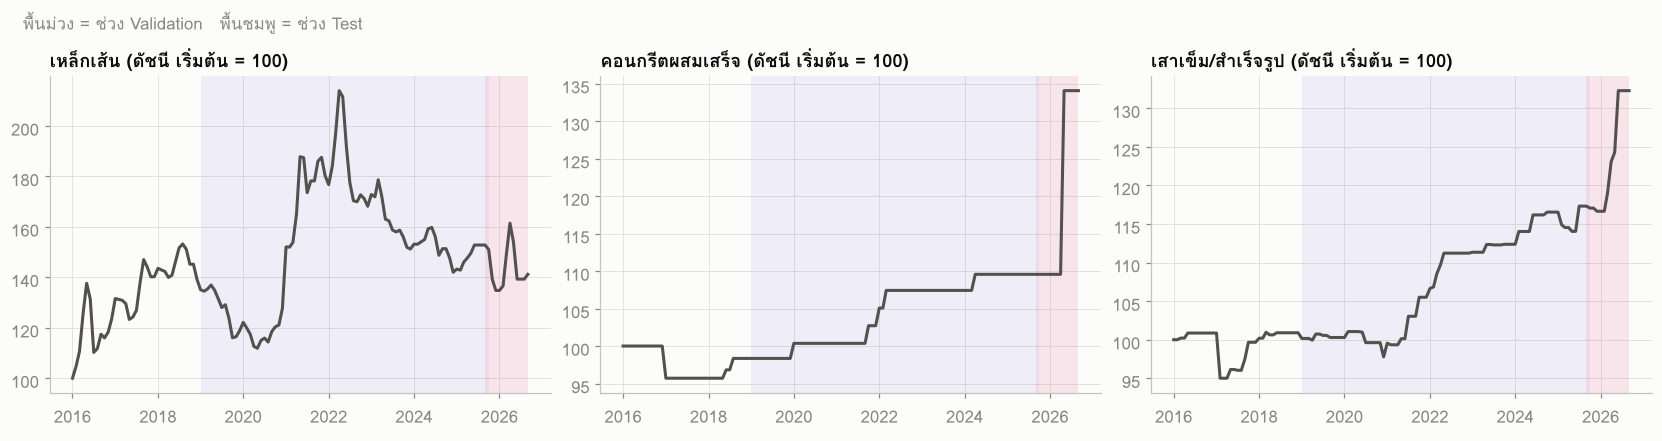

In [3]:
# @title 2.2 ราคาเปลี่ยนไปอย่างไรในช่วง 10 ปี { display-mode: "form" }
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), layout="constrained")
for ax, code_ in zip(axes, ["STR-01", "STR-06", "STR-08"]):
    g = P[P.categoryCode.astype(str) == code_].groupby("date")["ret1"].mean().fillna(0)
    idx = 100 * np.exp(g.cumsum())
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2025-10-01"), color=SPLIT["Validation"], alpha=0.08, lw=0)
    ax.axvspan(pd.Timestamp("2025-09-01"), latest, color=SPLIT["Test"], alpha=0.18, lw=0)
    ax.plot(idx.index, idx.values, color=SERIES, lw=2)
    ax.set_title(f"{CAT[code_]} (ดัชนี เริ่มต้น = 100)", loc="left")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("พื้นม่วง = ช่วง Validation   พื้นชมพู = ช่วง Test", x=0.01, ha="left", fontsize=11, color=MUTED)
plt.show()

เหล็กเส้นขึ้นแรง 2 ช่วง คือปี 2564–2565 และ มี.ค.–มิ.ย. 2569 ส่วนคอนกรีตผสมเสร็จกับเสาเข็มขยับเป็นขั้นบันได นาน ๆ ครั้ง เช่น คอนกรีตผสมเสร็จขึ้นทีเดียว 20–25% ใน พ.ค. 2569 ช่วง Test (พื้นชมพู) จึงมีทั้งเหล็กพุ่งแล้วลงและคอนกรีตกระโดด ทายยากกว่าปีปกติ

## 3. ตรวจและทำความสะอาดข้อมูล

เราเทียบข้อมูลกับเว็บ สนค. ทุกจุด (24,163 จุด) ตรงกันทั้งหมด ไม่มีแถวซ้ำ หน่วยตรงกับเว็บ แต่เจอ 3 เรื่องที่ต้องจัดการ:

| เรื่องที่เจอ | เราทำอะไร |
|---|---|
| สนค. เปลี่ยนรหัสเหล็กเส้น 2 ครั้ง (ปี 2561 และ 2569) รหัสใหม่จึงมีประวัติแค่ไม่กี่เดือน | จับคู่รหัสเก่ากับรหัสใหม่ 39 คู่ (สเปก ขนาด หน่วยเดียวกัน ราคาต่อกันห่างไม่เกิน 15%) แล้วต่อประวัติเข้าด้วยกัน |
| วัสดุบนเว็บ 100 รายการไม่มีราคาล่าสุด: 39 เป็นรหัสเก่าที่ต่อกับรหัสใหม่แล้ว ที่เหลือเลิกเก็บราคาจริง บางตัวหยุดตั้งแต่ปี 2559 | เก็บประวัติไว้ฝึกโมเดล แต่ไม่ทายและซ่อนจากเว็บ เหลือวัสดุที่ทาย 188 รายการ |
| เดือนที่ขาดหาย | ช่องว่างไม่เกิน 2 เดือน เติมด้วยการลากเส้นตรง ช่องว่างยาวกว่านั้นใช้เฉพาะช่วงหลังช่องว่าง |
| ราคาหลายหมวดไม่เปลี่ยนเกือบทุกเดือน | ข้อมูลถูกต้อง ราคา สนค. ขยับเป็นขั้นบันได เรื่องนี้ทำให้ทายยากที่สุด (ดูกราฟ 3.2) |

เราไม่เติมหรือแก้ค่า target และไม่ตัดราคาที่กระโดด เพราะตรวจแล้วเป็นราคาจริง

In [4]:
# @title 3.1 ตัวอย่างรหัสเหล็กเส้นที่ต่อกัน { display-mode: "form" }
links = pd.read_csv(f"{ROOT}/ml/out/series_links.csv", parse_dates=["old_last", "new_first"])
links = links[links.accepted]
print(f"ต่อรหัสทั้งหมด {len(links)} คู่")
show = links.groupby(links.new_first.dt.year).head(2)
display(pd.DataFrame({
    "ชื่อเดิม": show.old_name, "ชื่อใหม่": show.new_name,
    "รหัสเดิมหยุด": show.old_last.map(th), "รหัสใหม่เริ่ม": show.new_first.map(th),
    "ราคาขยับตอนต่อ (%)": show.change * 100,
}).reset_index(drop=True))

ต่อรหัสทั้งหมด 39 คู่


,ชื่อเดิม,ชื่อใหม่,รหัสเดิมหยุด,รหัสใหม่เริ่ม,ราคาขยับตอนต่อ (%)
0,เหล็กเส้นกลมผิวเรียบ SR.24 ยาว 10 เมตร ศก. 6 มม.,เหล็กเส้นกลมผิวเรียบ SR.24 มอก. 20-2559 ขนาดเส้นผ่านศูนย์กลาง 6 มม. ยาว 10 เมตร,มี.ค. 2569,เม.ย. 2569,8.00
1,เหล็กเส้นกลมผิวเรียบ SR.24 ยาว 10 เมตร ศก. 9 มม.,เหล็กเส้นกลมผิวเรียบ SR.24 มอก. 20-2559 ขนาดเส้นผ่านศูนย์กลาง 9 มม. ยาว 10 เมตร,มี.ค. 2569,เม.ย. 2569,8.29
2,เหล็กเส้นกลมผิวข้ออ้อย SD.40 (Tempcort) ยาว 10 เมตร ศก. 10 มม.,เหล็กเส้นกลมผิวข้ออ้อย SD.40 ศก.10 มม. ยาว 10 เมตร (Tempcore),พ.ค. 2561,มิ.ย. 2561,4.17
3,เหล็กเส้นกลมผิวข้ออ้อย SD.40 (Tempcort) ยาว 10 เมตร ศก. 12 มม.,เหล็กเส้นกลมผิวข้ออ้อย SD.40 ศก.12 มม. ยาว 10 เมตร (Tempcore),พ.ค. 2561,มิ.ย. 2561,3.47


ทุกวัสดุรวมกัน: ราคาเท่าเดือนก่อน 75% ของเดือน


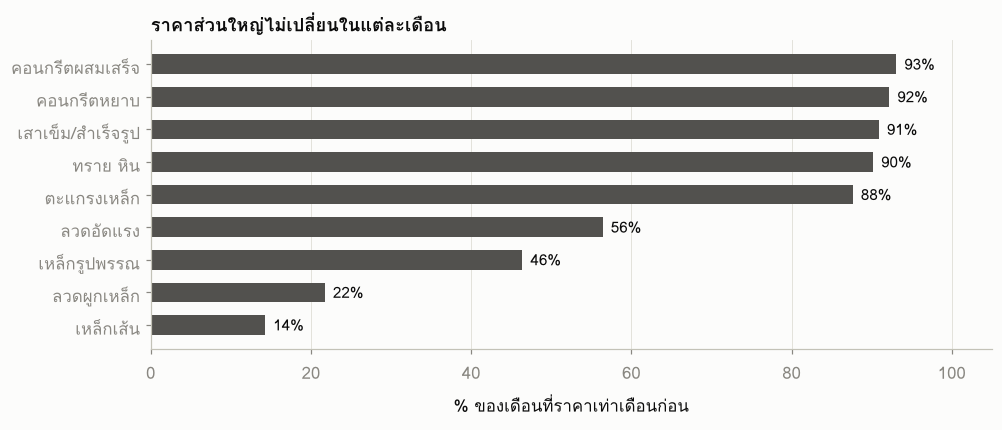

In [5]:
# @title 3.2 ราคาไม่เปลี่ยนจากเดือนก่อนกี่ % ของเดือน { display-mode: "form" }
x = P[P.ret1.notna()].assign(same=lambda d: d.ret1.abs() < 1e-9, หมวด=lambda d: d.categoryCode.astype(str).map(CAT))
share = x.groupby("หมวด")["same"].mean().mul(100).sort_values()
print(f"ทุกวัสดุรวมกัน: ราคาเท่าเดือนก่อน {x.same.mean():.0%} ของเดือน")
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
ax.barh(share.index, share.values, color=SERIES, height=0.6)
for y, v in enumerate(share.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=10, color=INK)
ax.set_xlim(0, 105)
ax.set_xlabel("% ของเดือนที่ราคาเท่าเดือนก่อน")
ax.grid(axis="y", visible=False)
ax.set_title("ราคาส่วนใหญ่ไม่เปลี่ยนในแต่ละเดือน", loc="left")
plt.show()

- **คอนกรีต เสาเข็ม ตะแกรงเหล็ก:** ราคาเท่าเดิมราว 9 ใน 10 เดือน ทายว่า "ไม่เปลี่ยน" ก็ถูกเกือบตลอด
- **เหล็กเส้น ลวดผูกเหล็ก:** ราคาเปลี่ยนเกือบทุกเดือน แต่ขึ้นหรือลงเดายาก หมวดนี้ทำให้ทายผิดมากสุด (ดูข้อ 11)

โมเดลที่จะชนะต้องรู้ว่า **เดือนไหน** ราคาจะขยับ และขยับ **ขึ้นหรือลง**

## 4. สร้างฟีเจอร์ (Feature Engineering)

**สิ่งที่ให้โมเดลทาย (target):** % ที่ราคาจะเปลี่ยนจากเดือนนี้ เช่น ราคาวันนี้ 100 บาท อีก 1 เดือนเป็น 103 บาท target = +3% (ในโค้ดใช้ log(103/100) ≈ 0.03) แล้วแปลงกลับเป็นบาทตอนวัดผล

ทำไมไม่ทายราคาตรง ๆ: ราคาวัสดุต่างกันหลายพันเท่า (ตารางด้านล่าง) ถ้าแปลงเป็น % ทุกวัสดุจะอยู่ในหน่วยเดียวกัน โมเดลตัวเดียวจึงเรียนจากทุกวัสดุพร้อมกันได้

**ฟีเจอร์ 52 ตัว** ทุกตัวใช้เฉพาะข้อมูลที่รู้แล้ว ณ เดือนที่ทาย ปัจจัยภายนอกใช้ค่าเดือนเดียวกับราคาล่าสุดได้ เพราะ สนค. ประกาศราคาเดือน ก.ย. ราววันที่ 9 ต.ค. ตอนนั้นรู้ราคาตลาดเดือน ก.ย. ครบแล้ว ยกเว้นดัชนีเศษเหล็กที่ออกช้า เราใช้ค่าเดือนก่อนหน้า

In [6]:
# @title 4.1 ช่วงราคาวัสดุ และกลุ่มฟีเจอร์ { display-mode: "form" }
import json
from global_model import feature_cols

catalog = {m["id"]: m for m in json.load(open(f"{ROOT}/frontend/src/data/structural-materials.json", encoding="utf-8"))["materials"]}
now = P[(P.date == latest) & P.material_id.isin(active)].sort_values("price").iloc[[0, -1]]
display(pd.DataFrame({"วัสดุ": [catalog[i]["name"] for i in now.material_id],
                      f"ราคา {th(latest)} (บาท)": now.price.values,
                      "ต่อ": [catalog[i]["unit"] for i in now.material_id]}, index=["ถูกสุด", "แพงสุด"]))

cols = feature_cols(P)
groups = [
    ("ราคาตัวเองย้อนหลัง", "ราคาขยับกี่ % ใน 1, 2, 3, 6, 12 เดือน และแกว่งแค่ไหน",
     lambda c: c.startswith(("ret", "vol"))),
    ("จังหวะการเปลี่ยนราคา", "ผ่านมากี่เดือนแล้วตั้งแต่ราคาเปลี่ยนครั้งล่าสุด เปลี่ยนครั้งล่าสุดเท่าไร ปีที่แล้วเปลี่ยนกี่ครั้ง",
     lambda c: c in ("since_change", "last_change", "changes12")),
    ("ราคาเทียบช่วง 12 เดือน", "ราคาตอนนี้สูงหรือต่ำกว่าค่าเฉลี่ย สูงสุด ต่ำสุด ของปีที่ผ่านมา",
     lambda c: c.startswith(("dev_", "fam_dev"))),
    ("วัสดุกลุ่มเดียวกัน", "เดือนนี้วัสดุกลุ่มเดียวกันขยับเท่าไร กี่ % ขึ้น กี่ % ลง (สนค. มักปรับทั้งกลุ่มพร้อมกัน)",
     lambda c: c.startswith(("fam_", "cat_")) and not c.startswith("fam_dev")),
    ("ข้อมูลประจำตัว", "หมวด กลุ่มย่อย และเดือนของปี",
     lambda c: c in ("categoryCode", "familyCode", "month")),
    ("ปัจจัยภายนอก", "ปัจจัย 8 ตัว + แร่เหล็กคิดเป็นเงินบาท: ขยับกี่ % ใน 1 และ 3 เดือน และห่างจากค่าเฉลี่ย 12 เดือนเท่าไร",
     lambda c: c.endswith(("_r1", "_r3", "_dev12")) and not c.startswith(("fam_", "cat_", "dev_"))),
]
rows, used = [], set()
for name, meaning, rule in groups:
    fs = [c for c in cols if rule(c) and c not in used]
    used |= set(fs)
    rows.append({"กลุ่ม": name, "จำนวน": len(fs), "ความหมาย": meaning, "ตัวอย่าง": ", ".join(fs[:4]) + (" ..." if len(fs) > 4 else "")})
display(pd.DataFrame(rows).set_index("กลุ่ม"))
print(f"รวม {sum(r['จำนวน'] for r in rows)} ฟีเจอร์ (ครบ {len(cols)} ตัว: {len(used) == len(cols)})")

,วัสดุ,ราคา ก.ย. 2569 (บาท),ต่อ
ถูกสุด,ตะแกรงเหล็กเส้นกลมผิวเรียบ สี่เหลี่ยมจัตุรัส ศก. 4.0 มม. ขนาดตาราง 0.25 x 0.25 ม. ตรา TM,27.0,ตร.ม.
แพงสุด,ลวดเหล็กเสริมคอนกรีตอัดแรง (PC STRAND) ชนิดตีเกลียว 7 เส้น ประเภท 1860 ขนาดเส้นผ่านศูน...,68000.0,ตัน


,จำนวน,ความหมาย,ตัวอย่าง
กลุ่ม,,,
ราคาตัวเองย้อนหลัง,7,"ราคาขยับกี่ % ใน 1, 2, 3, 6, 12 เดือน และแกว่งแค่ไหน","ret1, ret2, ret3, ret6 ..."
จังหวะการเปลี่ยนราคา,3,ผ่านมากี่เดือนแล้วตั้งแต่ราคาเปลี่ยนครั้งล่าสุด เปลี่ยนครั้งล่าสุดเท่าไร ปีที่แล้วเปลี...,"since_change, last_change, changes12"
ราคาเทียบช่วง 12 เดือน,4,ราคาตอนนี้สูงหรือต่ำกว่าค่าเฉลี่ย สูงสุด ต่ำสุด ของปีที่ผ่านมา,"dev_mean12, dev_max12, dev_min12, fam_dev_mean12"
วัสดุกลุ่มเดียวกัน,8,เดือนนี้วัสดุกลุ่มเดียวกันขยับเท่าไร กี่ % ขึ้น กี่ % ลง (สนค. มักปรับทั้งกลุ่มพร้อมกัน),"fam_ret1, fam_ret3, fam_up, fam_down ..."
ข้อมูลประจำตัว,3,หมวด กลุ่มย่อย และเดือนของปี,"categoryCode, familyCode, month"
ปัจจัยภายนอก,27,ปัจจัย 8 ตัว + แร่เหล็กคิดเป็นเงินบาท: ขยับกี่ % ใน 1 และ 3 เดือน และห่างจากค่าเฉลี่ย ...,"brent_crude_usd_barrel_r1, brent_crude_usd_barrel_r3, fx_usd_thb_r1, fx_usd_thb_r3 ..."


รวม 52 ฟีเจอร์ (ครบ 52 ตัว: True)


## 5. แบ่งข้อมูล: Train / Validation / Test

ข้อมูลราคาเป็นลำดับเวลา ถ้าสุ่มแบ่งแถว โมเดลจะได้เห็นราคาในอนาคตตอนฝึก ผลจะดูดีเกินจริง เราจึงแบ่งตามเวลาแบบ **walk-forward**:

1. ยืนที่เดือนหนึ่ง เรียกว่า "จุดเริ่ม"
2. ฝึกโมเดลด้วยข้อมูลที่รู้คำตอบแล้ว ณ เดือนนั้นเท่านั้น (Train)
3. ทายราคาอีก 1, 2, 3 เดือน แล้วเทียบกับราคาจริง
4. เลื่อนจุดเริ่มไปข้างหน้า ฝึกใหม่ แล้วทำซ้ำ

| ชุด | จุดเริ่ม | จำนวนการทาย | ใช้ทำอะไร |
|---|---|---:|---|
| Validation | 27 จุด ทุก 3 เดือน ม.ค. 2562 – ก.ค. 2568 | 13,680 | เลือกโมเดลและจูนค่า ครอบช่วงเหล็กพุ่งปี 2564–2565 |
| Test | 12 จุด ทุกเดือน ก.ย. 2568 – ส.ค. 2569 | 6,093 | วัดผลสุดท้าย ไม่แตะตอนเลือกหรือจูนโมเดล |

**กติกาที่ตั้งไว้ก่อนเริ่ม:** โมเดลต้องชนะ Naive ทั้งใน Validation และ Test ถึงจะเอาขึ้นเว็บ ถ้าชนะแค่ชุดเดียว ถือว่าบังเอิญ

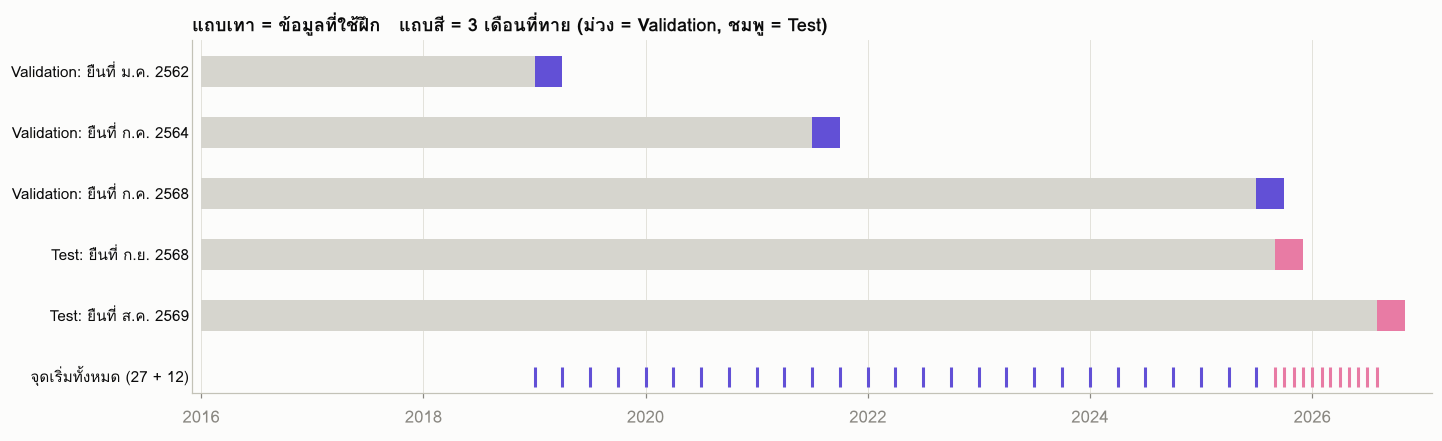

In [7]:
# @title 5.1 ภาพการแบ่งข้อมูล { display-mode: "form" }
cv_origins = list(pd.date_range("2019-01-01", latest - pd.DateOffset(months=14), freq="3MS"))
test_origins = [latest - pd.DateOffset(months=k) for k in range(12, 0, -1)]
examples = [("Validation", cv_origins[0]), ("Validation", cv_origins[10]), ("Validation", cv_origins[-1]),
            ("Test", test_origins[0]), ("Test", test_origins[-1])]
num = mdates.date2num
start = P.date.min()
fig, ax = plt.subplots(figsize=(13, 3.9), layout="constrained")
for i, (split, o) in enumerate(examples):
    y = len(examples) - i
    ax.barh(y, num(o) - num(start), left=num(start), height=0.5, color=SPLIT["Train"])
    ax.barh(y, num(o + pd.DateOffset(months=3)) - num(o), left=num(o), height=0.5, color=SPLIT[split])
    ax.text(num(start) - 40, y, f"{split}: ยืนที่ {th(o)}", ha="right", va="center", fontsize=10, color=INK)
for split, origins in (("Validation", cv_origins), ("Test", test_origins)):
    ax.scatter([num(o) for o in origins], [0] * len(origins), marker="|", s=160, color=SPLIT[split], linewidths=2)
ax.text(num(start) - 40, 0, f"จุดเริ่มทั้งหมด ({len(cv_origins)} + {len(test_origins)})", ha="right", va="center", fontsize=10, color=INK)
ax.xaxis_date()
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_xlim(num(start) - 30, num(latest) + 150)
ax.set_title("แถบเทา = ข้อมูลที่ใช้ฝึก   แถบสี = 3 เดือนที่ทาย (ม่วง = Validation, ชมพู = Test)", loc="left")
plt.show()

## 6. วัดผลยังไง

| ตัววัด | ความหมาย | ค่าที่ดี |
|---|---|---|
| **MAE (%)** | ทายผิดเฉลี่ยกี่ % ของราคา เช่น ราคา 100 บาท MAE 2% = ผิดเฉลี่ย 2 บาท | ต่ำ |
| **RMSE (%)** | คล้าย MAE แต่นับการผิดก้อนใหญ่หนักกว่า | ต่ำ |
| **R² ของ % การเปลี่ยน** | โมเดลอธิบายการขึ้นลงของราคาได้กี่ส่วน 0 = ไม่ดีกว่าทายว่าไม่เปลี่ยน | ใกล้ 1 |

**กับดัก R²:** ถ้าวัด R² จากตัวราคา Naive ได้เกือบ 1 ทั้งที่ไม่ได้ทายอะไรเลย เหตุผลคือเสาเข็มราคาหลักพัน ลวดราคาหลักสิบ แค่รู้ว่าวัสดุไหนแพงกว่าก็ได้ R² สูงแล้ว เราจึงวัด R² จาก % การเปลี่ยนแทน ดูตัวอย่างด้านล่าง

In [8]:
# @title 6.1 R² ของ Naive: วัดจากราคา เทียบวัดจาก % การเปลี่ยน (ช่วง Test, ทาย 1 เดือน) { display-mode: "form" }
TE = pd.read_csv(f"{ROOT}/ml/out/compare_preds_test.csv", parse_dates=["origin"])
CV = pd.read_csv(f"{ROOT}/ml/out/compare_preds_cv.csv", parse_dates=["origin"])
g = TE[TE.h == 1]
r2 = lambda a, p: 1 - ((a - p) ** 2).sum() / ((a - a.mean()) ** 2).sum()
display(pd.DataFrame({"R²": [r2(g.actual, g.price), r2(g.y, 0 * g.y)]},
                     index=["วัดจากราคา (หลอกตา)", "วัดจาก % การเปลี่ยน (ใช้จริง)"]))

,R²
วัดจากราคา (หลอกตา),1.00
วัดจาก % การเปลี่ยน (ใช้จริง),-0.02


## 7. Baseline: เกณฑ์ขั้นต่ำ

Baseline คือวิธีง่ายที่สุดที่ไม่ต้องใช้ ML ถ้าโมเดล ML แพ้ baseline ก็ไม่มีเหตุผลจะใช้

| วิธี | ทายยังไง |
|---|---|
| **Naive** | ราคาเดือนหน้า = ราคาเดือนนี้ |
| Seasonal naive | ราคาเดือนหน้า = ราคาเดือนเดียวกันของปีที่แล้ว (เทียบส่วนต่างจากเดือนนี้) |
| Drift | ลากเส้นแนวโน้มเฉลี่ยจากอดีตต่อไปข้างหน้า |

In [9]:
# @title 7.1 เทียบ baseline 3 แบบ (MAE %) { display-mode: "form" }
L = np.log(P.pivot(index="date", columns="material_id", values="price"))
first = L.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan)
n = L.notna().cumsum()


def baselines(R):
    out = {}
    for h in (1, 2, 3):
        g = R[R.h == h]
        sn = (L.shift(12 - h) - L).stack().rename("d")          # ราคาเดือนเดียวกันปีก่อน
        dr = ((L - first) / (n - 1) * h).stack().rename("d")   # แนวโน้มเฉลี่ย × h
        key = pd.MultiIndex.from_arrays([g.origin, g.material_id])
        d_sn = sn.reindex(key).fillna(0).values                # ไม่มีประวัติพอ ใช้ Naive แทน
        d_dr = dr.reindex(key).fillna(0).values
        out[f"{h} เดือน"] = {"Naive": mae_pct(g.price, 0, g.actual), "Seasonal naive": mae_pct(g.price.values, d_sn, g.actual.values),
                             "Drift": mae_pct(g.price.values, d_dr, g.actual.values)}
    return pd.DataFrame(out)


display(pd.concat({"Validation": baselines(CV), "Test": baselines(TE)}, axis=1))

Validation                    Test                
                  1 เดือน 2 เดือน 3 เดือน 1 เดือน 2 เดือน 3 เดือน
Naive                0.67    1.35    2.14    1.75    3.47    5.06
Seasonal naive       5.82    5.74    5.82    6.96    7.27    7.55
Drift                0.83    1.63    2.55    1.90    3.69    5.32

Naive ชนะขาดทั้ง 2 ชุด Seasonal naive แย่สุด เพราะราคาวัสดุก่อสร้างไม่ขึ้นลงตามฤดูกาล เราลอง ETS (exponential smoothing) ด้วย `baseline.py` ก็แพ้ Naive เช่นกัน (Test 1.91 / 3.81 / 5.62% เทียบ Naive 1.69 / 3.43 / 5.10% บนชุดวัสดุของสคริปต์นั้น)

**Naive จึงเป็นเกณฑ์ที่โมเดล ML ทุกตัวต้องชนะ**

## 8. โมเดลและอัลกอริทึมที่ลอง

เราฝึก **โมเดลรวมตัวเดียวจากทุกวัสดุ** (global model) แทนการฝึกแยกทีละวัสดุ เพราะวัสดุแต่ละตัวเปลี่ยนราคาแค่ไม่กี่ครั้ง โมเดลรวมได้เรียนจากการเปลี่ยนราคาหลายพันครั้ง

| โมเดล | อัลกอริทึม | ทำงานยังไง |
|---|---|---|
| Linear (Huber) | Linear Regression | หาเส้นตรงที่ใกล้ข้อมูลที่สุด ทนค่าโดด ลองกับหมวดเหล็ก |
| Random Forest | Bagging | สร้างต้นไม้ตัดสินใจ 200 ต้น แต่ละต้นฝึกจากข้อมูลที่สุ่มมาคนละชุด แล้วเฉลี่ยคำตอบ |
| LightGBM | Gradient Boosting | สร้างต้นไม้ทีละต้น ต้นใหม่แก้จุดที่ต้นก่อนหน้าทายผิด |
| LightGBM 2 ขั้น | Classifier + Regressor | ขั้นแรกทายโอกาสที่ราคาจะเปลี่ยน ถ้าเกิน 85% ขั้นสองทายว่าเปลี่ยนเท่าไร ถ้าไม่ถึง ทายว่าเท่าเดิม |
| LSTM | Deep Learning (RNN) | อ่านข้อมูลย้อนหลัง 12 เดือนเป็นลำดับ แล้วทาย 1, 2, 3 เดือนพร้อมกัน |
| Logistic Regression | Classification | ทายโอกาสที่ราคาจะเปลี่ยน ใช้เทียบกับ LightGBM ในข้อ 12 |

**เทคนิค "ขยับครึ่งเดียว":** หารคำทายของโมเดลด้วย 2 คำทายจะเข้าใกล้ Naive ช่วยลดความเสียหายตอนโมเดลทายผิดทิศ

ช่องด้านล่างฝึกทุกโมเดลจริงที่จุดเริ่มเดียว (ก.ย. 2568, ทาย 1 เดือน) ให้เห็นโค้ดและค่าตั้งที่ใช้ ใช้เวลาราว 1 นาที

In [10]:
# 8.1 ฝึกทุกโมเดลที่จุดเริ่มเดียว
from compare_models import FIXED, LGBM_PICK, build_sequences, lstm_feature_cols, lstm_predict, rf_predict
from tune import fit_all as lightgbm_models

cols = feature_cols(P)
P2, seqs = build_sequences(P, lstm_feature_cols(P))   # LSTM: ลำดับ 12 เดือน × 32 ฟีเจอร์ ต่อแถว
for c in ("categoryCode", "familyCode"):
    P2[c] = P2[c].astype("category")

o, h = pd.Timestamp("2025-09-01"), 1
train = P2[(P2.date + pd.DateOffset(months=h) <= o) & P2[f"y{h}"].notna()]        # รู้คำตอบแล้ว ณ ก.ย. 2568
test = P2[(P2.date == o) & P2[f"y{h}"].notna() & P2.material_id.isin(active)]       # สิ่งที่ต้องทาย
print(f"ฝึกด้วย {len(train):,} แถว   ทาย {len(test):,} วัสดุ")

pred = {"naive": np.zeros(len(test))}

# LightGBM: ค่าตั้งที่จูนแล้วสำหรับทาย 1 เดือน + แบบ 2 ขั้น ขยับครึ่งเดียว
params, how = LGBM_PICK[h]
print("LightGBM:", params, "| แบบ:", how)
pred["lgbm"] = lightgbm_models(train, test, h, cols, {**params, **FIXED})[how]

# Random Forest: 200 ต้น ใบละอย่างน้อย 50 แถว สุ่มฟีเจอร์ครึ่งหนึ่งต่อการแตกกิ่ง
pred["rf"] = rf_predict(train, test, h, cols)

# LSTM: LSTM 32 หน่วย -> Dropout 0.2 -> ทาย 3 ระยะ, Adam lr 0.001, early stopping 4 รอบ
known = P2.assign(**{f"y{k}": P2[f"y{k}"].where(P2.date + pd.DateOffset(months=k) <= o) for k in (1, 2, 3)})
at_o = ((P2.date == o) & P2.material_id.isin(active)).values
out = lstm_predict(seqs, known, ((P2.date + pd.DateOffset(months=1) <= o) & P2.y1.notna()).values, at_o)
pos = {j: i for i, j in enumerate(np.where(at_o)[0])}
pred["lstm"] = np.array([out[pos[j], h - 1] for j in test.index])

actual = test.price * np.exp(test[f"y{h}"])
saved = TE[(TE.origin == o) & (TE.h == h)]
display(pd.DataFrame({
    "MAE (%) ที่เพิ่งฝึก": {MODEL[m][0]: mae_pct(test.price, d, actual) for m, d in pred.items()},
    "MAE (%) ในผลที่บันทึกไว้": {MODEL[m][0]: mae_pct(saved.price, saved[f"d_{m}"], saved.actual) for m in pred},
}))

ฝึกด้วย 21,602 แถว   ทาย 186 วัสดุ
LightGBM: {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 40, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0} | แบบ: ts_t85_half


,MAE (%) ที่เพิ่งฝึก,MAE (%) ในผลที่บันทึกไว้
Naive (baseline),0.86,0.86
LightGBM,0.86,0.86
Random Forest,0.94,0.94
LSTM,0.89,0.89


จุดเริ่มเดียวยังสรุปอะไรไม่ได้ ข้อ 10 รวมผลทุกจุดเริ่ม (Random Forest และ LSTM สุ่มน้ำหนักเริ่มต้น ตัวเลขบนเครื่องอื่นอาจต่างจากผลที่บันทึกไว้เล็กน้อย)

## 9. จูนโมเดล (Hyperparameter Tuning)

**LightGBM:** สุ่มค่าตั้ง 20 ชุด + ค่าเริ่มต้น 1 ชุด (Random Search) จาก 7 ค่าในตารางด้านล่าง ใช้ข้อมูล Validation อย่างเดียว:

1. **รอบคัด:** ทดสอบทั้ง 21 ชุดบน 9 จุดเริ่ม
2. **รอบตัดสิน:** 5 ชุดที่ดีที่สุด + ค่าเริ่มต้น ทดสอบเต็ม 27 จุด
3. เลือกชุดที่ดีที่สุดแยกตามระยะทาย แล้ววัดบน Test ครั้งเดียว

**สิ่งอื่นที่จูน**

| โมเดล | จูนอะไร | ได้ค่าไหน |
|---|---|---|
| LightGBM 2 ขั้น | เกณฑ์ความมั่นใจก่อนขยับจาก Naive | 0.85 (ลอง 0.70 ด้วย) |
| ทุกโมเดล | ขยับเต็มหรือครึ่งเดียว | ครึ่งเดียวดีกว่าทุกครั้ง |
| ทุกโมเดล | ปัจจัยภายนอกเดือนเดียวกันหรือหน่วง 1 เดือน | เดือนเดียวกัน (ดีขึ้นเล็กน้อย) |
| Random Forest | ขนาดใบขั้นต่ำ กัน overfit | 50 แถว |
| LSTM | จำนวนรอบฝึก | หยุดเมื่อผลบนข้อมูล 10% ล่าสุดของ Train ไม่ดีขึ้น 4 รอบ (early stopping) |

In [11]:
# @title 9.1 ช่วงค่าที่สุ่ม และผลรอบตัดสิน (Validation, MAE %) { display-mode: "form" }
from tune import SPACE

meaning = {"num_leaves": "จำนวนใบสูงสุดต่อต้น (ต้นซับซ้อนแค่ไหน)", "learning_rate": "ต้นใหม่แก้ต้นเก่าแรงแค่ไหน",
           "n_estimators": "จำนวนต้นไม้", "min_child_samples": "ข้อมูลขั้นต่ำต่อใบ (กัน overfit)",
           "subsample": "สุ่มแถวกี่ % ต่อต้น", "colsample_bytree": "สุ่มฟีเจอร์กี่ % ต่อต้น",
           "reg_lambda": "ลงโทษค่าที่ใหญ่เกิน (กัน overfit)"}
display(pd.DataFrame({"ค่าที่สุ่มเลือก": {k: ", ".join(map(str, v)) for k, v in SPACE.items()}, "ความหมาย": meaning}))

T = pd.read_csv(f"{ROOT}/ml/out/tune_results.csv")
best = T[T.candidate != "naive"].groupby(["config", "h"])["cv_mae"].min().unstack()
best.index = [f"config {i}" + (" (ค่าเริ่มต้น)" if i == 0 else "") for i in best.index]
best.loc["Naive (baseline)"] = T[T.candidate == "naive"].groupby("h")["cv_mae"].first()
best.columns = [f"{h} เดือน" for h in best.columns]
display(best.sort_values("1 เดือน"))

,ค่าที่สุ่มเลือก,ความหมาย
num_leaves,"7, 15, 31, 63",จำนวนใบสูงสุดต่อต้น (ต้นซับซ้อนแค่ไหน)
learning_rate,"0.01, 0.03, 0.1",ต้นใหม่แก้ต้นเก่าแรงแค่ไหน
n_estimators,"100, 300, 600",จำนวนต้นไม้
min_child_samples,"20, 40, 100, 200",ข้อมูลขั้นต่ำต่อใบ (กัน overfit)
subsample,"0.7, 0.9",สุ่มแถวกี่ % ต่อต้น
colsample_bytree,"0.5, 0.8, 1.0",สุ่มฟีเจอร์กี่ % ต่อต้น
reg_lambda,"0.0, 1.0, 10.0",ลงโทษค่าที่ใหญ่เกิน (กัน overfit)


,1 เดือน,2 เดือน,3 เดือน
Naive (baseline),0.67,1.35,2.14
config 0 (ค่าเริ่มต้น),0.67,1.44,2.29
config 5,0.68,1.43,2.20
config 11,0.68,1.44,2.26
config 7,0.68,1.41,2.25
config 9,0.69,1.45,2.24
config 1,0.69,1.44,2.24


จูนแล้วยังไม่มีชุดไหนชนะ Naive ใน Validation ค่าตั้งที่ต่างกันให้ผลต่างกันไม่ถึง 0.1 จุด % แปลว่าปัญหาไม่ได้อยู่ที่ค่าตั้งของโมเดล

## 10. ผลเทียบทุกโมเดล

ทุกโมเดลทดสอบแบบเดียวกัน: 27 จุดเริ่มใน Validation และ 12 จุดใน Test ฝึกใหม่ทุกจุดเริ่ม

In [12]:
# @title 10.1 ตารางผล { display-mode: "form" }
NAMES = {"naive": "Naive (baseline)", "lgbm": "LightGBM (จูนแล้ว)", "rf": "Random Forest", "rf_half": "Random Forest ขยับครึ่งเดียว",
         "lstm": "LSTM", "lstm_half": "LSTM ขยับครึ่งเดียว"}


def score(R, kind):
    out = {}
    for m in NAMES:
        row = {}
        for h in (1, 2, 3):
            g = R[R.h == h]
            pe = (g.price * np.exp(g[f"d_{m}"]) - g.actual) / g.actual * 100
            row[f"{h} เดือน"] = {"MAE": pe.abs().mean(), "RMSE": np.sqrt((pe ** 2).mean()),
                                 "R2": 1 - ((g.y - g[f"d_{m}"]) ** 2).sum() / ((g.y - g.y.mean()) ** 2).sum()}[kind]
        out[NAMES[m]] = row
    return pd.DataFrame(out).T


def highlight_best(df):
    return df.style.format("{:.2f}").highlight_min(axis=0, props="font-weight:bold; background-color:#e6efe9")


print("MAE (%) ยิ่งต่ำยิ่งดี")
display(pd.concat({"Validation": score(CV, "MAE"), "Test": score(TE, "MAE")}, axis=1).pipe(highlight_best))
print("RMSE (%) ช่วง Test ยิ่งต่ำยิ่งดี")
display(score(TE, "RMSE").pipe(highlight_best))
print("R² ของ % การเปลี่ยน ช่วง Test (0 = ไม่ดีกว่าทายว่าไม่เปลี่ยน)")
display(score(TE, "R2").style.format("{:.2f}"))

MAE (%) ยิ่งต่ำยิ่งดี


RMSE (%) ช่วง Test ยิ่งต่ำยิ่งดี


,1 เดือน,2 เดือน,3 เดือน
Naive (baseline),4.15,6.42,7.99
LightGBM (จูนแล้ว),4.05,6.33,7.87
Random Forest,3.90,6.26,7.48
Random Forest ขยับครึ่งเดียว,3.97,6.26,7.68
LSTM,4.04,6.17,7.68
LSTM ขยับครึ่งเดียว,4.08,6.26,7.79


R² ของ % การเปลี่ยน ช่วง Test (0 = ไม่ดีกว่าทายว่าไม่เปลี่ยน)


,1 เดือน,2 เดือน,3 เดือน
Naive (baseline),-0.02,-0.04,-0.09
LightGBM (จูนแล้ว),0.03,-0.01,-0.05
Random Forest,0.10,0.03,0.04
Random Forest ขยับครึ่งเดียว,0.06,0.02,-0.01
LSTM,0.02,0.02,-0.03
LSTM ขยับครึ่งเดียว,0.01,-0.00,-0.05


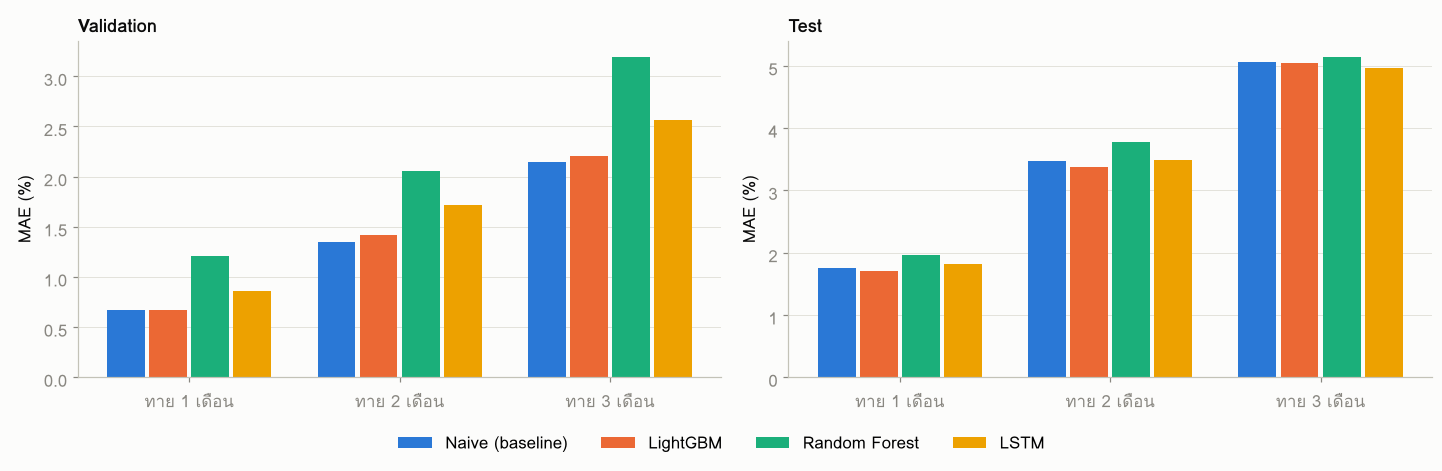

In [13]:
# @title 10.2 กราฟเทียบ MAE { display-mode: "form" }
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for ax, (name, R) in zip(axes, (("Validation", CV), ("Test", TE))):
    s = score(R, "MAE")
    for k, m in enumerate(MODEL):
        vals = s.loc[NAMES[m]].values
        ax.bar(np.arange(3) + (k - 1.5) * 0.2, vals, width=0.18, color=MODEL[m][1], label=MODEL[m][0])
    ax.set_xticks(range(3), ["ทาย 1 เดือน", "ทาย 2 เดือน", "ทาย 3 เดือน"])
    ax.set_ylabel("MAE (%)")
    ax.grid(axis="x", visible=False)
    ax.set_title(name, loc="left")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=4, loc="outside lower center")
plt.show()

**อ่านผล**

- **Validation:** ไม่มีโมเดลไหนชนะ Naive LightGBM เสมอที่ 1 เดือน Random Forest และ LSTM แพ้ชัดเจน
- **Test:** LightGBM และ LSTM ชนะเล็กน้อย (ไม่เกิน 0.1 จุด %) แต่ Validation ไม่ยืนยัน ตามกติกาจึงถือว่าบังเอิญ
- **RMSE:** Random Forest ต่ำสุดใน Test เพราะลดการผิดก้อนใหญ่ได้บ้าง แต่ MAE สูงกว่า เพราะทาย "ขยับนิดหน่อย" ทุกวัสดุ ทั้งที่ราคาส่วนใหญ่นิ่ง
- **R²:** ทุกโมเดลใกล้ 0 คืออธิบายการขึ้นลงของราคาแทบไม่ได้

**การทดลองก่อนหน้า (ช่วง Test เดียวกัน, MAE %)**

| การทดลอง | 1 / 2 / 3 เดือน | Naive | ผล |
|---|---|---|---|
| LightGBM ตัวแรก (ปัจจัย 6 ตัว ยังไม่จูน) | 1.88 / 3.91 / 5.85 | 1.75 / 3.47 / 5.06 | แพ้ทุกระยะ |
| LightGBM 2 ขั้น (p > 0.85) | 1.66 / 3.65 / 5.50 | 1.75 / 3.47 / 5.06 | ชนะเฉพาะ 1 เดือน Validation ไม่ยืนยัน |
| ใช้ปัจจัยภายนอกเดือนเดียวกัน | 1.65 / 3.43 / 5.15 | 1.75 / 3.47 / 5.06 | ชนะ 1–2 เดือน Validation ไม่ยืนยัน |
| Linear (Huber) เฉพาะเหล็กเส้น ทาย 3 เดือน | 7.75 | 9.93 | ชนะใน Test แต่ Validation แพ้หนัก |

## 11. ดู Residual

residual = (ราคาจริง − ราคาที่ทาย) / ราคาจริง × 100 ค่าบวกคือทายต่ำไป ค่าลบคือทายสูงไป

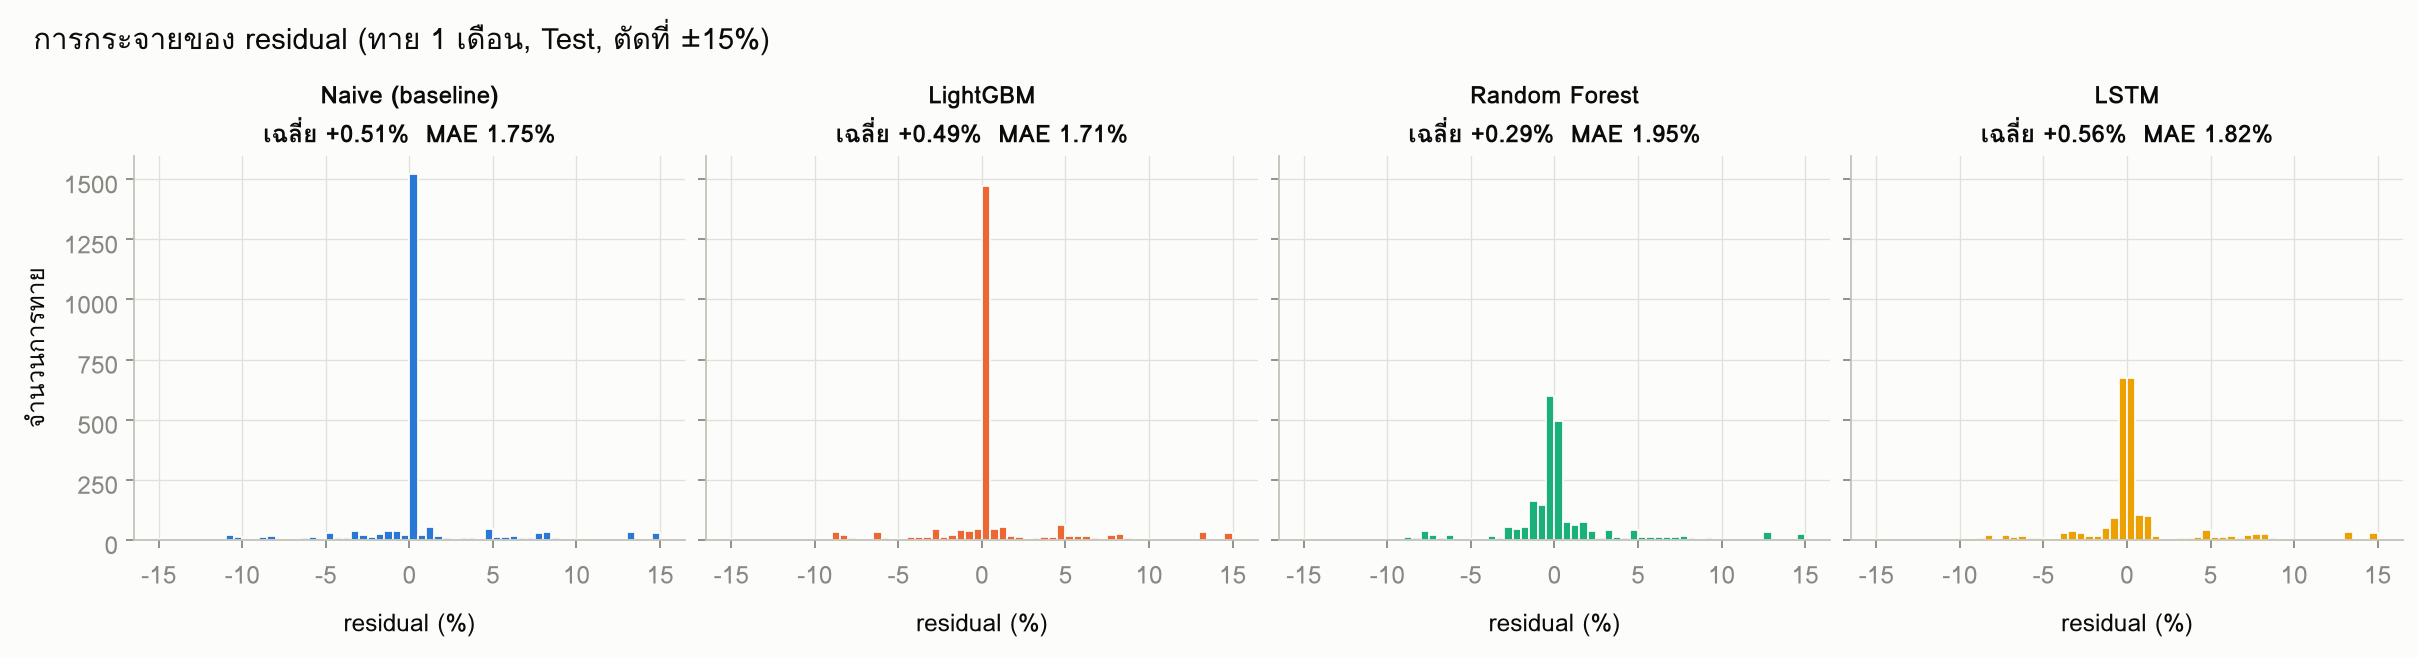

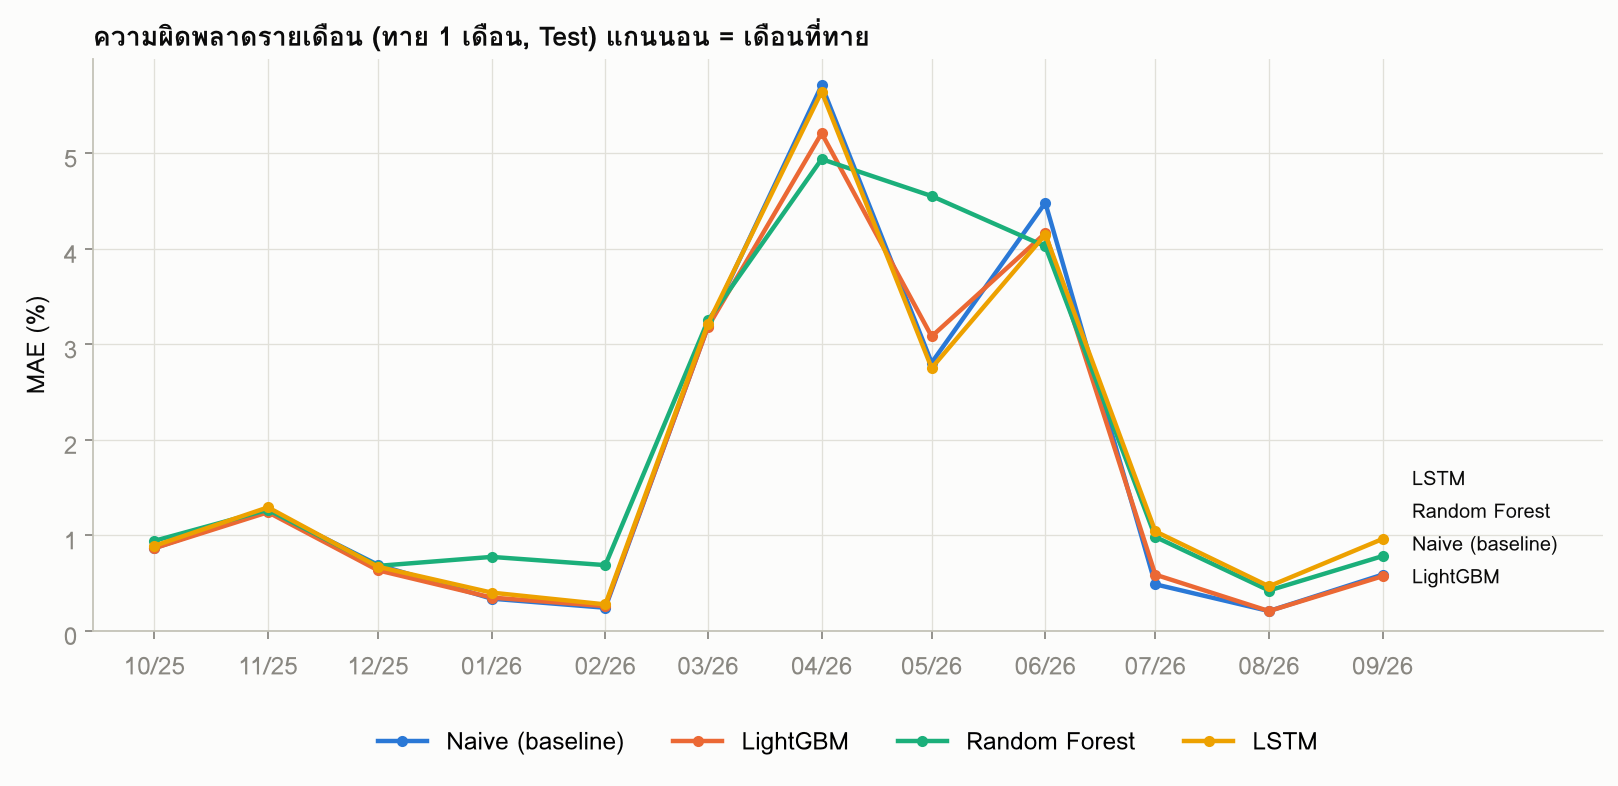

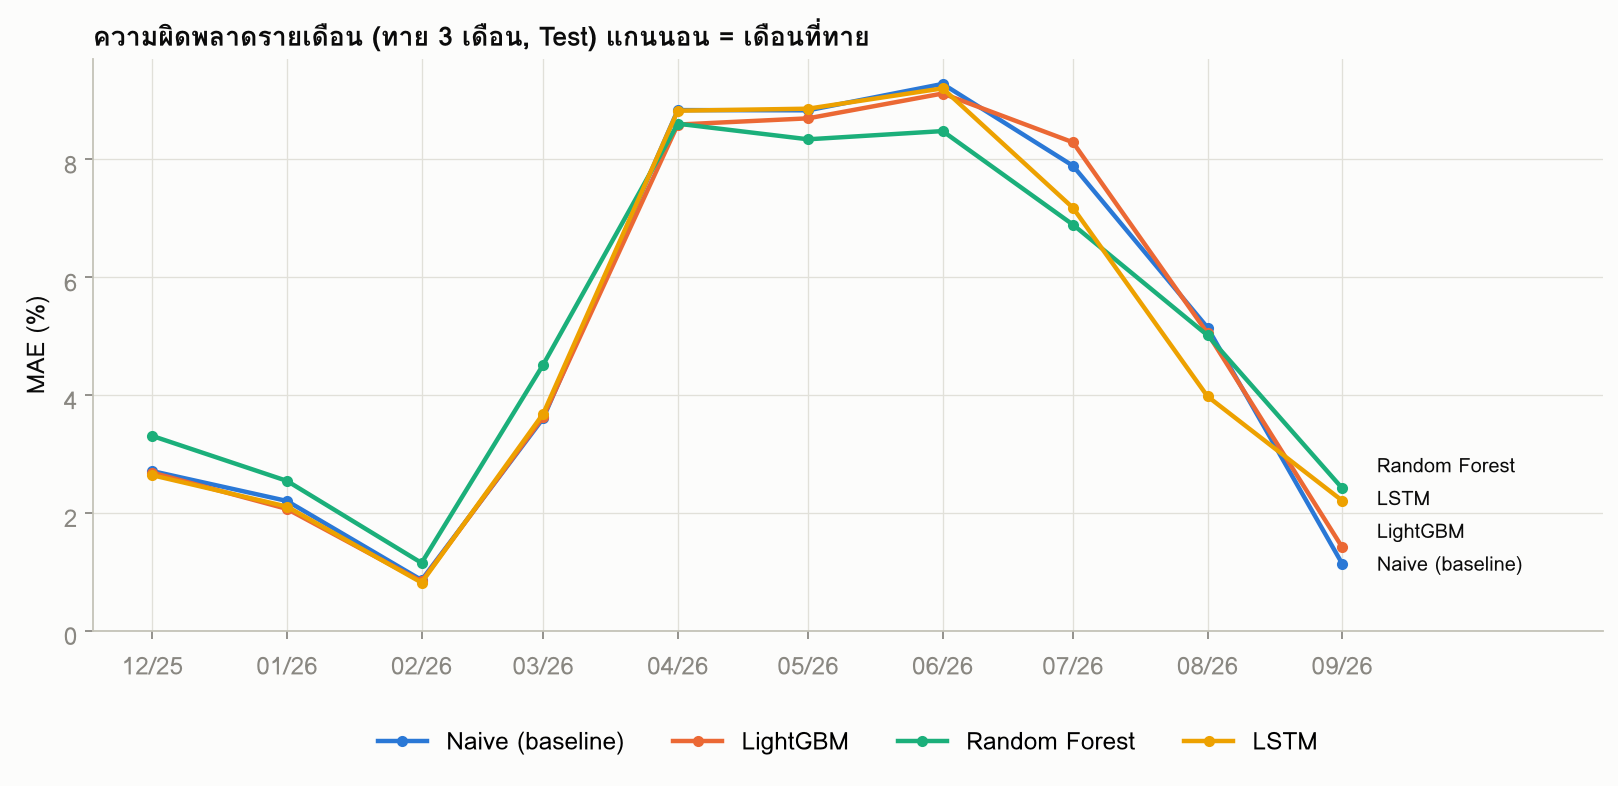

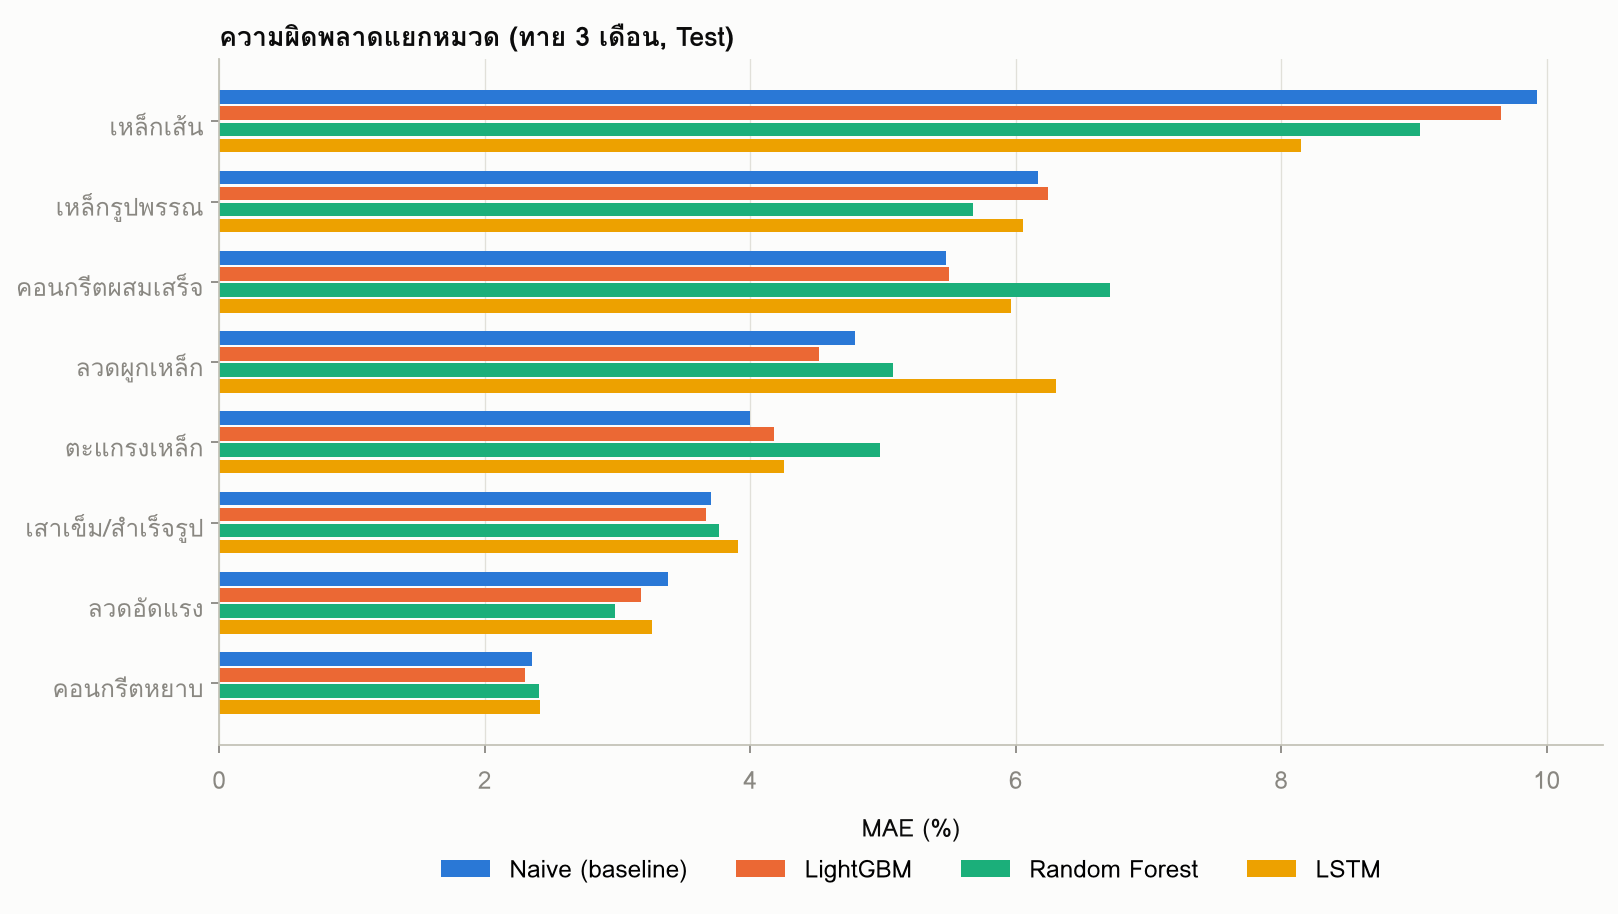

In [14]:
# @title 11.1 กราฟ residual ช่วง Test { display-mode: "form" }
import residuals

for h in (1, 3):
    R = residuals.load(h)
    residuals.residual_hist(R, h)
    residuals.error_by_month(R, h)
    residuals.error_by_category(R, h)
for f in ("residual_hist_h1", "error_by_month_h1", "error_by_month_h3", "error_by_category_h3"):
    display(Image(f"{ROOT}/ml/report_figures/{f}.png", width=1000))

**อ่านกราฟ**

- **Histogram:** Naive กับ LightGBM มีแท่งสูงที่ 0 คือทายถูกพอดีราว 2 ใน 3 ของครั้ง Random Forest กับ LSTM กระจายรอบ 0 เพราะทายขยับเล็กน้อยเกือบทุกครั้ง
- **ค่าเฉลี่ยเป็นบวกทุกโมเดล:** ปีทดสอบราคาขึ้น ทุกโมเดลทายต่ำไป
- **รายเดือน:** ความผิดพลาดกองอยู่ที่ มี.ค.–ก.ค. 2569 และทุกโมเดลพลาดพร้อมกัน แปลว่าข้อมูลที่มีไม่มีสัญญาณเตือนล่วงหน้าของช่วงนั้น เปลี่ยนอัลกอริทึมก็ไม่ช่วย
- **รายหมวด:** เหล็กเส้นผิดมากสุด (ทาย 3 เดือนผิดเฉลี่ยเกือบ 10%) คอนกรีตหยาบผิดน้อยสุด

## 12. ป้าย "ราคามีโอกาสเปลี่ยน" (Classification)

โมเดลทายตัวเลขราคาไม่ชนะ Naive แต่เราพบว่าโมเดลบอกได้ดีว่า **ราคากำลังจะขยับ** แม้ไม่รู้ทิศ เว็บจึงใช้ส่วนนี้ขึ้นป้ายเตือนเมื่อโอกาสถึง 70%

- **target:** ราคาเดือนที่ทายต่างจากเดือนนี้หรือไม่ (1 = เปลี่ยน, 0 = เท่าเดิม)
- **เทียบ 3 แบบ:** กฎตามหมวด (baseline: โอกาส = สัดส่วนเดือนที่หมวดนั้นเคยเปลี่ยน), Logistic Regression, LightGBM
- **แบ่งข้อมูล:** walk-forward ชุดเดียวกับข้อ 5

| ตัววัด | ความหมาย |
|---|---|
| Precision | ขึ้นป้ายแล้ว ราคาเปลี่ยนจริงกี่ % |
| Recall | ราคาที่เปลี่ยนจริงทั้งหมด ขึ้นป้ายไว้ทันกี่ % |
| F1 | ค่ากลางของ Precision กับ Recall |
| AUC | เรียงลำดับ "วัสดุไหนน่าจะเปลี่ยน" ได้ดีแค่ไหน 0.5 = เดาสุ่ม, 1 = สมบูรณ์ |

Accuracy ใช้ตัวเดียวไม่ได้ เพราะทาย "ไม่เปลี่ยน" ทุกตัวก็ได้ 68% แล้ว

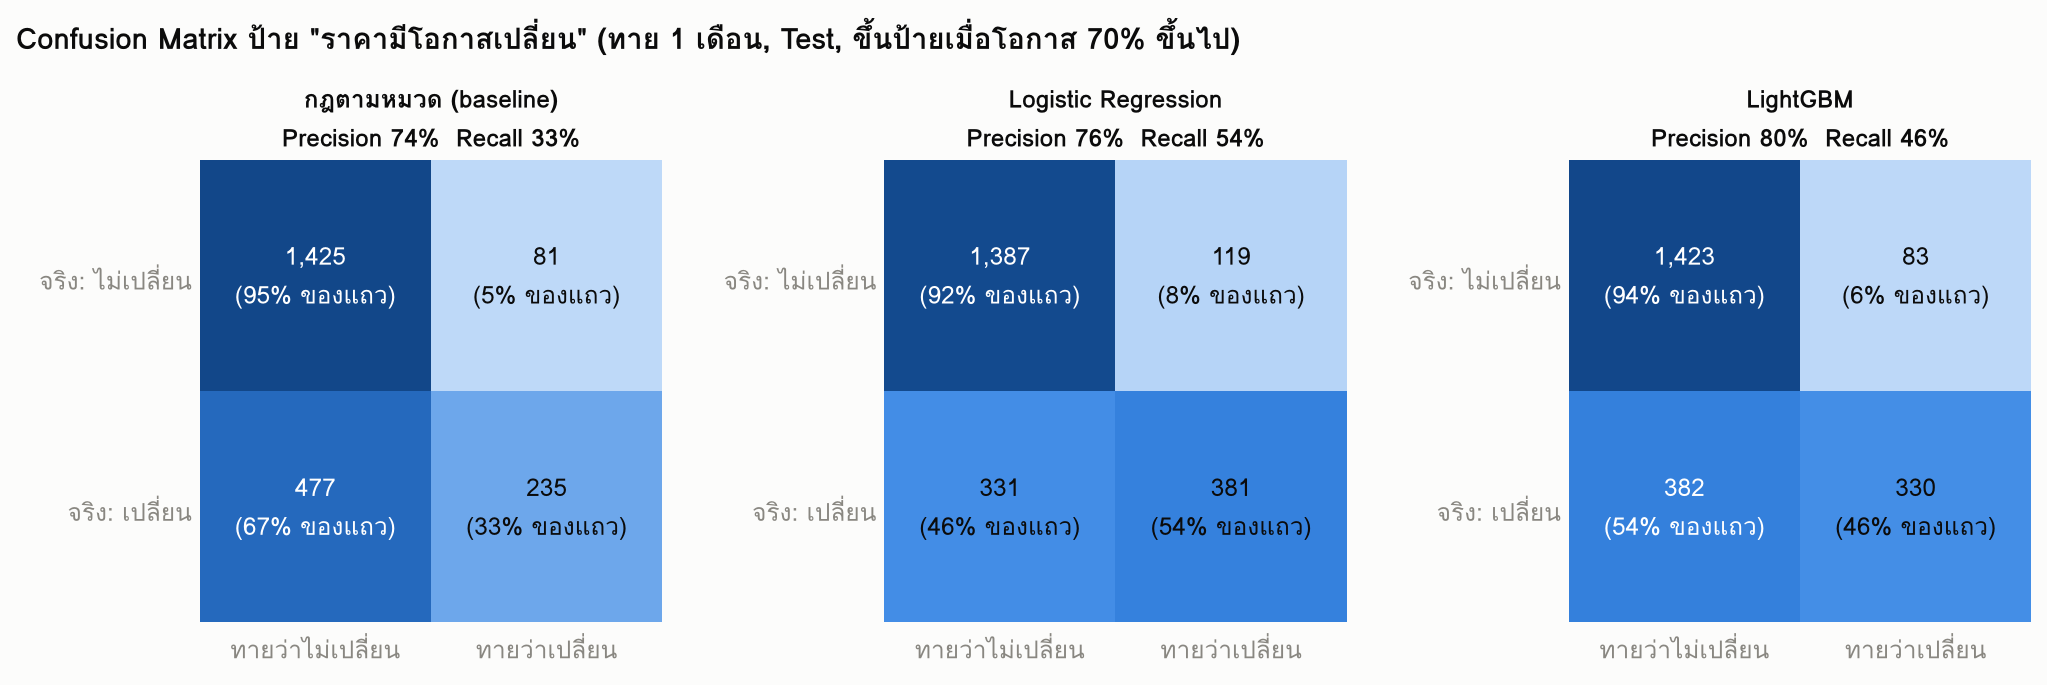

In [15]:
# @title 12.1 ผลช่วง Test ที่เกณฑ์ 70% และ Confusion Matrix { display-mode: "form" }
import classify_signal

C = pd.read_csv(f"{ROOT}/ml/out/classify_preds.csv")
CT = C[C.split == "test"]
m = classify_signal.metrics(CT, thresholds=(0.7,))
m["model"] = m.model.map(classify_signal.NAMES)
m["h"] = m.h.map(lambda h: f"ทาย {h} เดือน")
display(m.drop(columns=["threshold"]).set_index(["h", "model"])
        .style.format({"AUC": "{:.2f}", "Accuracy": "{:.0%}", "Precision": "{:.0%}", "Recall": "{:.0%}", "F1": "{:.2f}", "ขึ้นป้าย (%)": "{:.0f}"}))
classify_signal.plot_confusion(CT)
display(Image(f"{ROOT}/ml/report_figures/confusion_h1.png", width=1000))

**อ่านผล**

- ทั้ง Logistic Regression และ LightGBM ชนะกฎตามหมวด
- **LightGBM** มี AUC สูงสุดทุกระยะ ขึ้นป้ายน้อยกว่าแต่แม่นกว่า (Precision 80% ที่ 1 เดือน)
- **Logistic Regression** จับการเปลี่ยนได้มากกว่า (Recall 54%) แลกกับ Precision ที่ลดลงเล็กน้อย
- เว็บเลือก LightGBM เพราะป้ายที่ขึ้นแล้วผิดบ่อยจะทำให้ผู้ใช้ไม่เชื่อป้าย ตัวเลขบนเว็บผ่านการปรับโอกาสให้ตรงกับที่เกิดจริง (calibration) จึงต่างจากตารางนี้เล็กน้อย

## 13. ปัญหาที่เจอและสิ่งที่ลอง

| ลำดับ | ปัญหา | เราลองอะไร | ผล |
|---:|---|---|---|
| 1 | เหล็กเส้นรหัสใหม่มีประวัติแค่ 5 เดือน | ต่อรหัสเก่ากับรหัสใหม่ 39 คู่ | เหล็กเส้น 25 จาก 26 รายการมีประวัติพอทาย |
| 2 | 100 วัสดุเลิกเก็บราคา เว็บโชว์ราคาเก่าหลายปี | แยกวัสดุที่ยังเก็บราคา ซ่อนตัวที่เลิกแล้ว | ทาย 188 วัสดุที่ยังมีราคา |
| 3 | LightGBM ตัวแรกแพ้ Naive | ดูผลแล้วพบว่าโมเดลทายขยับทุกเดือนทั้งที่ราคานิ่ง | สร้างโมเดล 2 ขั้น ขยับเฉพาะตอนมั่นใจ |
| 4 | Validation ช่วงแรก (12 เดือน) ราคานิ่งเกินไป เลือกโมเดลผิด | ขยาย Validation เป็น 27 จุด 7 ปี | ผลน่าเชื่อขึ้น ครอบช่วงเหล็กพุ่ง |
| 5 | ข้อมูลเหล็กฟิวเจอร์สเรียงวันที่แบบ ปี-วัน-เดือน | ตรวจและแปลงวันที่ใหม่ | ใช้ข้อมูลนี้ได้ถูกต้อง |
| 6 | ปัจจัยภายนอกหน่วง 1 เดือน | ใช้ค่าเดือนเดียวกัน (สนค. ประกาศวันที่ 9 ของเดือนถัดไป) | ดีขึ้นเล็กน้อยใน Test Validation ไม่ยืนยัน |
| 7 | ค่าตั้งโมเดลอาจไม่ดี | Random Search 21 ชุด | ต่างกันไม่ถึง 0.1 จุด % |
| 8 | อัลกอริทึมอาจไม่เหมาะ | Random Forest, LSTM, Linear | แพ้ Naive ใน Validation |
| 9 | ไม่มีข้อมูลบอกล่วงหน้า | หาเพิ่ม: ราคาเหล็กต่างจังหวัด, ราคาร้านค้า, ค่าไฟ Ft, ราคานำเข้า (UN Comtrade), มาตรการกันทุ่มตลาด | ไม่มีตัวไหนรู้ก่อนราคา สนค. (สหสัมพันธ์ไม่เกิน 0.22) |

## 14. สรุป

**สิ่งที่ใช้บนเว็บ**

| ส่วน | ใช้อะไร | ผล |
|---|---|---|
| ทายราคา 1–3 เดือน | Naive + ช่วงราคาต่ำ–สูงจากความผิดพลาดในอดีต | ช่วงราคาครอบราคาจริง 83% |
| ป้าย "ราคามีโอกาสเปลี่ยน" | LightGBM Classifier | ขึ้นป้ายแล้วราคาเปลี่ยนจริง 80% |

**แม่นแค่ไหน (ภาษาคน)**

- ปีปกติ: ราคา 100 บาท ทาย 1 เดือนผิดเฉลี่ยราว 70 สตางค์
- ปีล่าสุดที่เหล็กแกว่งแรง: ทาย 1 เดือนผิดเฉลี่ย 1.75 บาท ทาย 3 เดือนผิดเฉลี่ยราว 5 บาท
- เหล็กเส้นยากสุด: ทาย 1 เดือนผิดเฉลี่ย 778 บาทต่อตัน ทาย 3 เดือน 1,948 บาทต่อตัน

**ทำไม ML ไม่ชนะ Naive**

คอนกรีตและเสาเข็มราคานิ่งเกือบทุกเดือน Naive จึงถูกเกือบตลอด ส่วนเหล็กขยับทุกเดือน แต่ข้อมูลที่เรามีบอกได้แค่ว่า "จะขยับ" ไม่รู้ว่าขึ้นหรือลง ทุกโมเดลจึงพลาดพร้อมกันในเดือนเดียวกัน สิ่งที่ขาดคือข้อมูลที่รู้ก่อน อัลกอริทึมที่ดีกว่าช่วยไม่ได้

**ถ้าจะทำต่อ**

หาข้อมูลที่รู้ก่อน สนค. ประกาศ เช่น ราคาที่โรงงานเหล็กประกาศรายสัปดาห์ แหล่งฟรีย้อนหลังไม่มี ต้องซื้อหรือเก็บเองต่อเนื่อง

## ภาคผนวก: รันการทดลองเต็มใหม่

ตั้ง `RUN_FULL = True` แล้วรันช่องนี้ ผลใหม่จะเขียนทับไฟล์ใน `thaitay_colab/ml/out/` แล้วรันข้อ 6 ถึง 12 ซ้ำเพื่อดูผลใหม่

| การทดลอง | เวลาโดยประมาณบน Colab |
|---|---|
| เทียบ Naive, LightGBM, Random Forest, LSTM | 25–40 นาที |
| ป้าย Classification | 30–60 นาที |
| จูน LightGBM | 60–90 นาที |

In [16]:
RUN_FULL = False

if RUN_FULL:
    import compare_models, classify_signal, tune
    compare_models.main()
    classify_signal.main()
    tune.main()